In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

SEED = 42
REVIEWS_FILE = "data/raw/All_Beauty.jsonl"
META_FILE = "data/raw/meta_All_Beauty.jsonl"

In [2]:
reviews = pd.read_json(REVIEWS_FILE, lines=True, convert_dates=False)
print(reviews.shape)

(701528, 10)


In [3]:
reviews.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5,Such a lovely scent but not overpowering.,"This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, med...",[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4,Works great but smells a little weird.,"This product does what I need it to do, I just wish it was odorless or had a soft coconut smell. Having my head smell like an orange coffee is offputting. (granted, I did know the smell was descri...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True
3,1,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1643393630220,0,True
4,5,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1609322563534,0,True


In [4]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 701528 entries, 0 to 701527
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   rating             701528 non-null  int64 
 1   title              701528 non-null  object
 2   text               701528 non-null  object
 3   images             701528 non-null  object
 4   asin               701528 non-null  object
 5   parent_asin        701528 non-null  object
 6   user_id            701528 non-null  object
 7   timestamp          701528 non-null  int64 
 8   helpful_vote       701528 non-null  int64 
 9   verified_purchase  701528 non-null  bool  
dtypes: bool(1), int64(3), object(6)
memory usage: 48.8+ MB


In [5]:
reviews["date"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews["year"] = reviews["date"].dt.year
reviews[["timestamp", "date", "year"]].head()

,timestamp,date,year
0,1588687728923,2020-05-05 14:08:48.923,2020
1,1588615855070,2020-05-04 18:10:55.070,2020
2,1589665266052,2020-05-16 21:41:06.052,2020
3,1643393630220,2022-01-28 18:13:50.220,2022
4,1609322563534,2020-12-30 10:02:43.534,2020


In [6]:
print("Reviews:              ", len(reviews))
print("Products (parent_asin):", reviews["parent_asin"].nunique())
print("Variants (asin):      ", reviews["asin"].nunique())
print("Users:                ", reviews["user_id"].nunique())
print("Date range:           ", reviews["date"].min().date(), "to", reviews["date"].max().date())

Reviews:               701528
Products (parent_asin): 112565
Variants (asin):       115709
Users:                 631986
Date range:            2000-11-01 to 2023-09-09


In [7]:
reviews.isna().sum()

rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
date                 0
year                 0
dtype: int64

In [8]:
star_counts = reviews["rating"].value_counts().sort_index()
star_percent = (star_counts / len(reviews) * 100).round(1)
pd.DataFrame({"reviews": star_counts, "percent": star_percent})

,reviews,percent
rating,,
1,102080,14.6
2,43034,6.1
3,56307,8.0
4,79381,11.3
5,420726,60.0


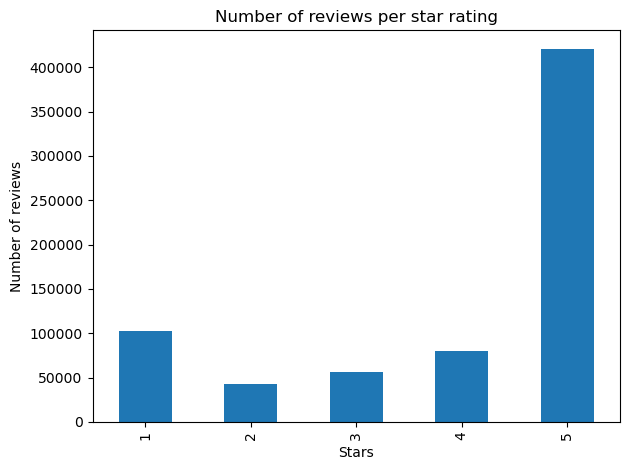

In [9]:
star_counts.plot(kind="bar")
plt.title("Number of reviews per star rating")
plt.xlabel("Stars")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.savefig("results/figures/eda_star_ratings.png", dpi=200)
plt.show()

In [10]:
reviews.groupby("year")["rating"].agg(["count", "mean"]).round(2)

,count,mean
year,,
2000,1,5.00
2001,12,4.58
2002,24,4.38
2003,56,4.34
2004,134,4.02
2005,267,3.93
2006,419,3.90
2007,1162,4.11
2008,1269,4.11


In [11]:
reviews["n_words"] = reviews["text"].fillna("").str.split().str.len()
reviews["n_words"].describe()

count    701528.000000
mean         32.750720
std          45.973273
min           0.000000
25%           8.000000
50%          19.000000
75%          40.000000
max        2585.000000
Name: n_words, dtype: float64

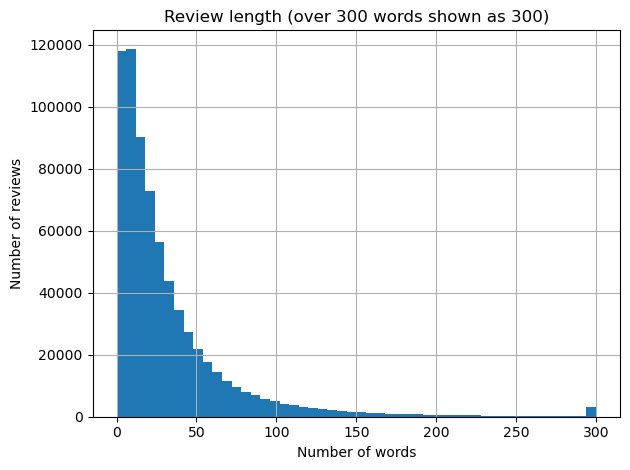

In [12]:
reviews["n_words"].clip(upper=300).hist(bins=50)
plt.title("Review length (over 300 words shown as 300)")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.savefig("results/figures/eda_review_length.png", dpi=200)
plt.show()

In [13]:
for n in [1, 3, 5, 10]:
    print(f"Reviews with fewer than {n} words:", (reviews["n_words"] < n).sum())

Reviews with fewer than 1 words: 720
Reviews with fewer than 3 words: 50058
Reviews with fewer than 5 words: 95705
Reviews with fewer than 10 words: 200388


In [14]:
reviews.loc[reviews["n_words"].between(1, 4), ["rating", "text"]].sample(10, random_state=SEED)

,rating,text
621949,5,My fav blush now
386854,5,Son presiosas
405927,5,Loveeeeee these
577823,5,love this one:))))))))
189059,4,Beautiful
342524,5,So cute!
564942,5,Easy to use
6782,4,Perfect
385284,5,best toe spacers ever!
271903,5,Love it


In [15]:
exact_dupes = reviews.duplicated(subset=["user_id", "parent_asin", "text"])
repeat_reviews = reviews.duplicated(subset=["user_id", "parent_asin"])

print("Exact duplicates (same user, product, text):", exact_dupes.sum())
print("Same user reviewed same product again:      ", repeat_reviews.sum())

Exact duplicates (same user, product, text): 7300
Same user reviewed same product again:       7599


In [16]:
reviews.loc[repeat_reviews, ["user_id", "parent_asin", "date", "rating", "text"]].head(10)

,user_id,parent_asin,date,rating,text
80,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B0B2L218H2,2020-11-19 19:33:29.168,4,"These Pinrose Gilded Fox petals are a fun way to try out a new scent! The box comes with 12 packets. Each packet has a fragrance infused towelette. They aren't too wet, but you are able to rub or ..."
243,AFXF3EGQTQDXMRLDWFU7UBFQZB7Q,B08HGZXLP6,2021-01-20 00:34:13.719,5,"There are four amber glass spray bottles in this set. In addition, six black labels, one stainless steel funnel, one glass eye dropper, one white marker, and four standard black caps are included...."
332,AFQQQ5LGNSQUEBGDCYBAZZE5T3DA,B08WCG4JCC,2020-09-09 16:50:55.886,5,I'm a curly girl. One of the constant struggles with my type of hair is that it may look dull sometimes since it's so dark. This shine spray is like a makeover in a bottle. It adds instant shine a...
655,AHU2GG5RF6YAEWUFNLH3QH5RHDNQ,B01DD1NOZU,2021-11-26 18:38:38.416,5,"So good for our hair, will purchase again"
1092,AEZP6Z2C5AVQDZAJECQYZWQRNG3Q,B08YJV9YL2,2020-11-01 15:13:41.231,4,"This is a nice inexpensive body wash. It comes in very nice packaging to be honest and makes for a great gift, especially with the holidays coming up. They also have the matching body lotion and a..."
1898,AG73BVBKUOH22USSFJA5ZWL7AKXA,B09J5TZ7HL,2018-09-15 01:42:40.642,5,"The needles in the eye microtip are not very long and they are very thin, so it is a breeze to go over your eye area and eyebrow area without pain and with ease. I want all of the needling attachm..."
2916,AHT6AM6BNIZUHFJB5V2M6XM72G7Q,B08WCG4JCC,2020-09-07 22:01:21.950,5,"This is an oily consistency, but it sprays easily and there is a heavy stream. I was surprised by that at first, but managed to rake it evenly through the rest of my hair. It soaked in pretty quic..."
3620,AES3YWD3ONJOUDRWFIV2ZO44QDAQ,B09G3KBK7Y,2022-02-22 07:53:42.892,3,"I really loved the idea of this Boiess Baby Cologne ""Les Enfants"" in White Blossom, and thought it would be perfect for myself since I don't like loud fragrances. The description of the scent prof..."
3762,AG63W2BMC4HRP76AMS36AYY64AHA,B08HGZXLP6,2021-01-08 17:33:06.966,5,"I'm very pleased with these glass bottles. The glass is thick and, while it's certainly not immune to breaking, it can deal with the occasional bump without a problem. Having it be tinted brown is..."
4323,AGQXJJKCSEMKU7K6DVM2BORDLTZA,B083PXJBVY,2022-04-22 13:30:12.976,5,"I don't know about scalp treatment, but my hair is so soft and it controls frizz. Smells like bananas while using, but rinsed clean."


In [17]:
has_html = reviews["text"].str.contains("<br|&amp;|&quot;|&#", na=False)
print("Reviews containing HTML code:", has_html.sum())
reviews.loc[has_html, "text"].head(3)

Reviews containing HTML code: 52883


36                                                                                           Rrain hats are really handy when<br />one doesn't have an umbrella, and<br />easy to carry in a purse or pocket.
39                                 Normally I like NYX products but not this one. It leaves a funny coating on your eyebrows and pushes them down so much they look thinner than they are.<br />Not worth it.
51    I'm loving this!<br />I've been looking for a great serum for fine lines and have tried many. However my skin can be very sensitive so with many that I've tried, I've found that I wake up with puf...
Name: text, dtype: object

In [18]:
per_product = reviews.groupby("parent_asin").size()
per_product.describe()

count    112565.000000
mean          6.232204
std          25.189840
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1962.000000
dtype: float64

In [19]:
for n in [11, 20, 30, 50, 100]:
    keep = per_product[per_product >= n]
    print(f"Products with >= {n} reviews: {len(keep)}  (total reviews: {keep.sum()})")

Products with >= 11 reviews: 11981  (total reviews: 449502)
Products with >= 20 reviews: 6044  (total reviews: 365702)
Products with >= 30 reviews: 3692  (total reviews: 309666)
Products with >= 50 reviews: 1902  (total reviews: 241730)
Products with >= 100 reviews: 744  (total reviews: 163106)


In [20]:
per_user = reviews.groupby("user_id").size()
print(pd.cut(per_user, [0, 1, 4, 9, np.inf], labels=["1", "2-4", "5-9", "10+"]).value_counts().sort_index())

1      583553
2-4     46813
5-9      1290
10+       330
Name: count, dtype: int64


In [21]:
print("Verified purchase share:", round(reviews["verified_purchase"].mean(), 3))
print(reviews["helpful_vote"].describe())
print("Reviews with 0 helpful votes:", (reviews["helpful_vote"] == 0).sum())

Verified purchase share: 0.905
count    701528.000000
mean          0.923588
std           5.471391
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max         646.000000
Name: helpful_vote, dtype: float64
Reviews with 0 helpful votes: 514089


In [22]:
print("Reviews on/after 30 Nov 2022:", (reviews["date"] >= "2022-11-30").sum())

Reviews on/after 30 Nov 2022: 18324


In [23]:
df = reviews.sort_values(["parent_asin", "timestamp", "user_id"]).reset_index(drop=True)

In [24]:
def average_of_previous_10(ratings):
    previous = ratings.shift(1)
    return previous.rolling(10, min_periods=10).mean()

df["prior_mean"] = df.groupby("parent_asin")["rating"].transform(average_of_previous_10)
df[["parent_asin", "date", "rating", "prior_mean"]].head(15)

,parent_asin,date,rating,prior_mean
0,0005946468,2018-02-02 04:54:01.775,5,NaN
1,0123034892,2017-09-26 17:25:51.406,5,NaN
2,0124784577,2019-06-24 23:29:59.244,5,NaN
3,0124784577,2019-09-01 01:23:54.115,5,NaN
4,0124784577,2019-09-09 14:59:29.877,3,NaN
5,0515059560,2014-09-17 02:00:11.000,4,NaN
6,0692508988,2016-03-24 21:27:06.000,5,NaN
7,069267599X,2016-10-21 16:55:20.000,5,NaN
8,069267599X,2016-12-02 16:42:57.000,5,NaN
9,069267599X,2017-02-16 19:14:35.000,5,NaN


In [25]:
has_crowd = df["prior_mean"].notna()
neg_vs_pos = (df["rating"] <= 2) & (df["prior_mean"] >= 4)
pos_vs_neg = (df["rating"] >= 4) & (df["prior_mean"] <= 2.5)

print("Reviews with 10 earlier reviews:     ", has_crowd.sum())
print("1-2 stars when crowd averaged >= 4:  ", neg_vs_pos.sum())
print("4-5 stars when crowd averaged <= 2.5:", pos_vs_neg.sum())

Reviews with 10 earlier reviews:      329692
1-2 stars when crowd averaged >= 4:   25374
4-5 stars when crowd averaged <= 2.5: 5459


In [26]:
crowd_type = pd.cut(df.loc[has_crowd, "prior_mean"], [0, 2.5, 4, 5.01],
                    labels=["negative crowd", "mixed crowd", "positive crowd"])
pd.crosstab(df.loc[has_crowd, "rating"], crowd_type)

prior_mean,negative crowd,mixed crowd,positive crowd
rating,,,
1,7678,24033,14572
2,1996,10380,7746
3,1749,12561,12002
4,1357,14748,20794
5,4102,62873,133101


In [27]:
df.loc[neg_vs_pos, ["rating", "prior_mean", "title", "text"]].sample(8, random_state=SEED)

,rating,prior_mean,title,text
612086,1,4.9,Can’t get it right,I’ve ordered this twice now to get the pictured and described “crewmate” among us temporary tattoos for a birthday party. Both times the label is over a different “video game” label and has the wr...
564399,1,4.0,Disappointed,Was working great for 2 months and then stopped working today completely. The handle kept heating up but no air would come out of the brush. I was worried it would catch on fire with how hot the h...
11682,1,4.4,Disappointed,Didn’t work out of the box. Still waiting for replacement
689074,1,4.1,No es de mi gusto,"Huele demasiado fuerte 🥹😭, me baja la presión 😭"
4176,1,4.2,"if it rusts like the 8170XL, don't buy it","I really liked using the 8170XL (didn't try the 8140XL), until the hinge at the razor's head started rusting. The head just falls off now...it's really easy to rinse.<br /><br />If the 8140XL rus..."
658612,1,4.5,It turns to powder and rolls off your skin,It blurs…. But it turns powdery and rolls off while you rub it in.
50349,1,4.3,Horrible quality,Looked like something from the dollar store. Nothing like the picture!
551300,1,4.4,Nooo,This once again is very thin and sheds miserably and don’t hold a curl hood at all.


In [28]:
meta = pd.read_json(META_FILE, lines=True, convert_dates=False)
print(meta.shape)
meta.head(3)

(112590, 14)


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,All Beauty,"Howard LC0008 Leather Conditioner, 8-Ounce (4-Pack)",4.8,10,[],[],NaN,"[{'thumb': 'https://m.media-amazon.com/images/I/41qfjSfqNyL._SS40_.jpg', 'large': 'https://m.media-amazon.com/images/I/41qfjSfqNyL.jpg', 'variant': 'MAIN', 'hi_res': None}, {'thumb': 'https://m.me...",[],Howard Products,[],"{'Package Dimensions': '7.1 x 5.5 x 3 inches; 2.38 Pounds', 'UPC': '617390882781'}",B01CUPMQZE,NaN
1,All Beauty,"Yes to Tomatoes Detoxifying Charcoal Cleanser (Pack of 2) with Charcoal Powder, Tomato Fruit Extract, and Gingko Biloba Leaf Extract, 5 fl. oz.",4.5,3,[],[],NaN,"[{'thumb': 'https://m.media-amazon.com/images/I/41b+11d5igL._SS40_.jpg', 'large': 'https://m.media-amazon.com/images/I/41b+11d5igL.jpg', 'variant': 'MAIN', 'hi_res': 'https://m.media-amazon.com/im...",[],Yes To,[],"{'Item Form': 'Powder', 'Skin Type': 'Acne Prone', 'Brand': 'Yes To', 'Age Range (Description)': 'Adult', 'Unit Count': '10 Fl Oz', 'Is Discontinued By Manufacturer': 'No', 'Item model number': 'S...",B076WQZGPM,NaN
2,All Beauty,Eye Patch Black Adult with Tie Band (6 Per Pack),4.4,26,[],[],NaN,"[{'thumb': 'https://m.media-amazon.com/images/I/31bz+uqzWCL._SS40_.jpg', 'large': 'https://m.media-amazon.com/images/I/31bz+uqzWCL.jpg', 'variant': 'MAIN', 'hi_res': None}, {'thumb': 'https://m.me...",[],Levine Health Products,[],{'Manufacturer': 'Levine Health Products'},B000B658RI,NaN


In [29]:
meta = meta[["parent_asin", "title", "store", "price", "main_category",
             "average_rating", "rating_number"]]
meta = meta.rename(columns={"title": "product_title"})
meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112590 entries, 0 to 112589
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   parent_asin     112590 non-null  object 
 1   product_title   112590 non-null  object 
 2   store           101259 non-null  object 
 3   price           17704 non-null   float64
 4   main_category   112590 non-null  object 
 5   average_rating  112590 non-null  float64
 6   rating_number   112590 non-null  int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [30]:
print("Each product appears once:", meta["parent_asin"].is_unique)
print("Duplicate product rows:", meta["parent_asin"].duplicated().sum())

Each product appears once: True
Duplicate product rows: 0


In [31]:
meta["price"] = pd.to_numeric(meta["price"], errors="coerce")
print("Products with a price:", meta["price"].notna().sum(), "of", len(meta))
meta["price"].describe()

Products with a price: 17704 of 112590


count    17704.00000
mean        27.25573
std         50.47202
min          0.01000
25%          9.99000
50%         16.99000
75%         29.90000
max       2548.98000
Name: price, dtype: float64

In [32]:
meta["main_category"].value_counts(dropna=False)

main_category
All Beauty        112135
Premium Beauty       455
Name: count, dtype: int64

In [33]:
match = reviews["parent_asin"].isin(meta["parent_asin"])
print("Reviews with product info:", match.sum(), "of", len(reviews))

Reviews with product info: 701528 of 701528


In [34]:
test_join = reviews.merge(meta, on="parent_asin", how="left")
print("Rows before:", len(reviews), "| Rows after:", len(test_join))
test_join[["parent_asin", "rating", "title", "product_title", "store", "price"]].head()

Rows before: 701528 | Rows after: 701528


,parent_asin,rating,title,product_title,store,price
0,B00YQ6X8EO,5,Such a lovely scent but not overpowering.,"Herbivore - Natural Sea Mist Texturizing Salt Spray (Coconut, 8 oz)",HERBIVORE,NaN
1,B081TJ8YS3,4,Works great but smells a little weird.,"All Natural Vegan Dry Shampoo Powder - Eco Friendly, Root Touch Up | Hair Powder Volumizer | For Brown Hair, Brunette and Dark Hair. (Brun + Application Brush) Two Goats Apothecary",Two Goats Apothecary,NaN
2,B097R46CSY,5,Yes!,"New Road Beauty - Creamsicle - Variety 3 Pack Paraffin Wax - Peach, Vanilla & Mango - Moisturize and Smooths Skin - Nourishing and Provides Massage Therapy",New Road Beauty,21.98
3,B09JS339BZ,1,Synthetic feeling,"muaowig Ombre Body Wave Bundles 1B Grey Human Hair Bundles 8 10 12 inch Hair Weave Body Wave Brazilian Remy Hair Bundles Ombre Hair Extensions 3 Bundles By Muao,Grey Body Wave",muaowig,NaN
4,B08BZ63GMJ,5,A+,"Yinhua Electric Nail Drill Kit Portable Professional Nail Drill Manicure Pen Shape Acrylic Nail Tools for Exfoliation Polishing with 6 Drill Bits and Sanding Bands for Home Salon (1 Set, green)",Yinhua,NaN


In [35]:
disagree = df["prior_mean"].notna() & (df["rating"] <= 2) & (df["prior_mean"] >= 4)

for n in [5, 10,15, 20, 25, 50]:
    all_pct = (df["n_words"] < n).mean() * 100
    dis_pct = (df.loc[disagree, "n_words"] < n).mean() * 100
    print(f"Under {n} words:  all reviews {all_pct:.1f}%  |  disagreeing reviews {dis_pct:.1f}%")

Under 5 words:  all reviews 13.6%  |  disagreeing reviews 8.3%
Under 10 words:  all reviews 28.6%  |  disagreeing reviews 21.8%
Under 15 words:  all reviews 40.6%  |  disagreeing reviews 34.1%
Under 20 words:  all reviews 50.2%  |  disagreeing reviews 44.6%
Under 25 words:  all reviews 58.5%  |  disagreeing reviews 53.8%
Under 50 words:  all reviews 81.2%  |  disagreeing reviews 79.4%


In [36]:
df_check = df.merge(meta[["parent_asin", "price"]], on="parent_asin", how="left")
disagree = df_check["prior_mean"].notna() & (df_check["rating"] <= 2) & (df_check["prior_mean"] >= 4)

print("Reviews with a price:            ", f"{df_check['price'].notna().mean()*100:.1f}%")
print("Disagreeing reviews with a price:", df_check.loc[disagree, "price"].notna().sum())
print("Reviews with 1+ helpful votes:   ", f"{(df_check['helpful_vote'] >= 1).mean()*100:.1f}%")
print("Disagreeing with 1+ votes:       ", f"{(df_check.loc[disagree, 'helpful_vote'] >= 1).mean()*100:.1f}%")
print(df_check["helpful_vote"].value_counts().sort_index().head(6))

Reviews with a price:             26.5%
Disagreeing reviews with a price: 9275
Reviews with 1+ helpful votes:    26.7%
Disagreeing with 1+ votes:        32.1%
helpful_vote
0    514089
1     98801
2     34266
3     16520
4      9514
5      5981
Name: count, dtype: int64
